# mmb0-1b_smb1-1b_1p

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 24.09.2024
- Date of Last Modification: 11.11.2024 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [ ]:
# NO BATCH TOKEN IN CONTEXT

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [4]:
import logging
import os
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from sklearn.model_selection import train_test_split

from nichejepa.datasets import prepare_dataset
from nichejepa.infer import infer
from nichejepa.train import train
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [5]:
# Set params
dataset = 'mmb0-1b_smb1-1b_1p'
tokenizer = 'cell_neighborhood'
load_timestamp = None # '14112024_064800_822', None
read_checkpoint = None # 'jepa-ep5.pth.tar', None

In [6]:
model_config_folder_path = '../../config/model'
artifacts_folder_path = '../../artifacts'
datasets_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'

In [7]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{tokenizer}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['meta']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

INFO:root:Loaded parameters from YAML file.


{'data': {'dataset_name': 'mmb0-1b_smb1-1b_1p',
  'raw_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_labels',
  'tokenized_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/gold/cell-neighborhood-tokenizer/mmb0-1b_smb1-1b_1p/mmb0-1b_smb1-1b_1p_shifted_log_862.dataset',
  'tokenizer_type': 'cell_neighborhood',
  'n_special_values': 7,
  'random_state': 0,
  'sample_subset': False,
  'split': 0.2,
  'stratify': False,
  'vocab_size': 1671,
  'seq_len_cell': 176,
  'seq_len_neighborhood': 309,
  'n_segments': 2,
  'sampling_strategy': None,
  'batch_size': 64,
  'num_workers': 6,
  'pin_memory': True},
 'meta': {'gt_type': 'counts',
  'enc_depth': 3,
  'enc_emb_dim': 768,
  'pred_depth': 1,
  'pred_emb_dim': 768,
  'special_tokens': ['batch'],
  'pos_learnable': False,
  'seg_learnable': False,
  'use_bfloat16': True},
 'mask': {'n_contexts': 1,
  'n_targets': 5,
  'block_masking': True,
  'context_mask_size': 200,
  'target_mask_s

In [8]:
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'../../artifacts/mmb0-1b_smb1-1b_1p/15112024_063153_874'

## 1.3 Create Train & Test Dataset

In [9]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'seg_tokens', 'cls_tokens'],
    num_rows: 69457
})

## 1.4 Run INIT Distributed

In [10]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2. Model Training

In [11]:
### Train model
train(params,
      train_dataset,
      test_dataset,
      save_folder_path=folder_path)

INFO:root:Initialized (rank/world-size) 0/1.
INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(1671, 768, padding_idx=0)
  (seg_embed): Embedding(10, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (

/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/helper.py:307: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if use_bfloat16 else None


INFO:root:Epoch 1


/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/train.py:491: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,


INFO:root:[1,     0] loss: 0.525 masks: 178.0 39.0 [wd: 4.00e-02] [lr: 2.00e-05] [mem: 8.64e+03] (897.3 ms)
INFO:root:[1,     0] grad_stats: [1.38e-03 1.27e-03] (1.54e-06, 3.08e-03)
INFO:root:[1,    20] loss: 0.475 masks: 153.7 33.8 [wd: 4.00e-02] [lr: 2.00e-05] [mem: 8.65e+03] (112.7 ms)
INFO:root:[1,    20] grad_stats: [5.61e-04 5.90e-04] (6.25e-07, 1.58e-03)
INFO:root:[1,    40] loss: 0.435 masks: 143.5 31.6 [wd: 4.00e-02] [lr: 2.00e-05] [mem: 8.65e+03] (91.9 ms)
INFO:root:[1,    40] grad_stats: [3.10e-04 3.68e-04] (2.91e-07, 1.01e-03)
INFO:root:[1,    60] loss: 0.403 masks: 136.3 30.2 [wd: 4.00e-02] [lr: 2.00e-05] [mem: 8.65e+03] (83.0 ms)
INFO:root:[1,    60] grad_stats: [1.96e-04 2.13e-04] (1.95e-07, 7.39e-04)
INFO:root:[1,    80] loss: 0.377 masks: 130.3 29.0 [wd: 4.00e-02] [lr: 2.00e-05] [mem: 8.65e+03] (77.1 ms)
INFO:root:[1,    80] grad_stats: [1.43e-04 1.57e-04] (1.44e-07, 5.58e-04)
INFO:root:[1,   100] loss: 0.356 masks: 125.3 28.0 [wd: 4.00e-02] [lr: 2.00e-05] [mem: 8.65e+

# 3. Analysis

## 3.1 Run Model Inference

In [17]:
# Set inference params
#folder_path = '../../artifacts/mmb0-1b_smb1-1b_1p/05112024_163055_362'
#params['state']['read_checkpoint'] = 'nichejepa-ep100.pth.tar'
exclude_unshared_tokens = False # True, False
agg_type = 'cls' # 'avg', 'weighted_avg', 'cls'

# Get gene tokens that do not overlap between gene panels to obtain excluded tokens
if exclude_unshared_tokens:
    with open(gene_panel_gene_mapping_file_path, 'rb') as file:
        gene_panel_gene_mapping = pickle.load(file)
    
    with open(token_dictionary_file_path, 'rb') as file:
        token_dictionary = pickle.load(file)
    
    genes_panel0 = set(gene_panel_gene_mapping['gene_panel0'])
    genes_panel1 = set(gene_panel_gene_mapping['gene_panel1'])
    
    overlapping_genes = list(genes_panel0.intersection(genes_panel1))
    non_overlapping_genes = list(genes_panel0.symmetric_difference(genes_panel1))
    
    overlapping_gene_tokens = [token_dictionary[gene] for gene in overlapping_genes if gene in token_dictionary]
    non_overlapping_gene_tokens = [token_dictionary[gene] for gene in non_overlapping_genes if gene in token_dictionary]
else:
    non_overlapping_gene_tokens = None

In [18]:
# Run model inference
adata = infer(params,
              test_dataset, # train_dataset, test_dataset
              load_folder_path=folder_path,
              agg_type=agg_type,
              masked_tokens=non_overlapping_gene_tokens,
              agg_excluded_tokens=excluded_tokens if exclude_unshared_tokens else None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{agg_type}'
            f'{"_shared_genes" if exclude_unshared_tokens and "cls" not in agg_type else ("_all_genes" if "cls" not in agg_type else "")}.h5ad')

INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(1671, 768, padding_idx=0)
  (seg_embed): Embedding(10, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100, 768)
  (special_

/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/helper.py:78: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(r_path, map_location=torc

INFO:root:Loaded pretrained encoder from epoch 100 with msg: <All keys matched successfully>.
INFO:root:Loaded pretrained predictor from epoch 100 with msg: <All keys matched successfully>.
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:Loaded pretrained target encoder from epoch 100 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: ../../artifacts/mmb0-1b_smb1-1b_1p/15112024_063153_874/nichejepa-latest.pth.tar.


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:274: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
272it [01:04,  4.22it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/merge.py:1358: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


## 3.2 Plot Embeddings

In [19]:
adata.obs['nichecompass_latent_cluster'] = adata.obs['nichecompass_latent_cluster'].astype(str).astype('category')
adata.obs["batch"] = [cell_id[2:8] for cell_id in adata.obs.index.tolist()]

layer = params['meta']['enc_depth'] - 1

... storing 'batch' as categorical
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a 

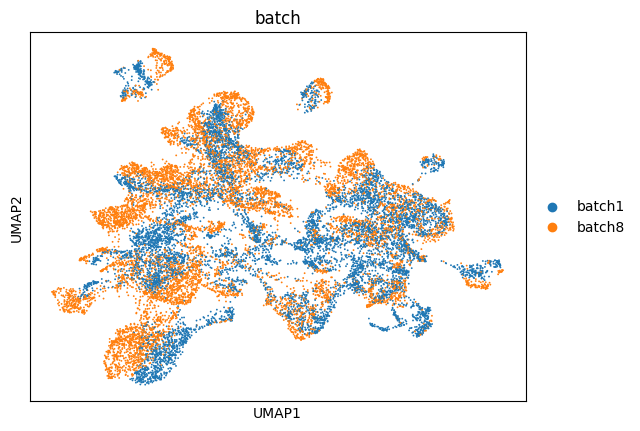

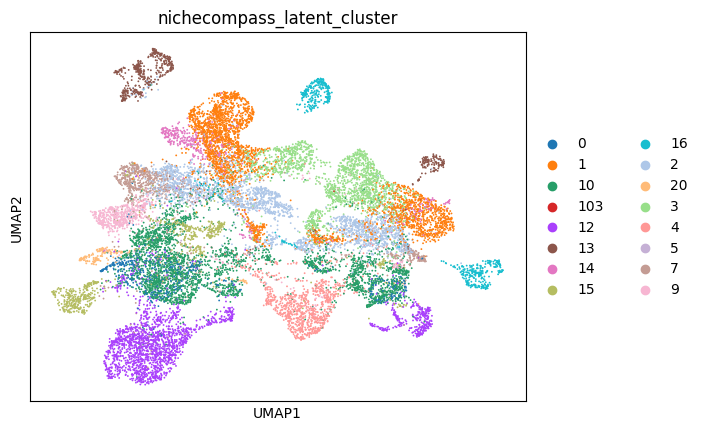

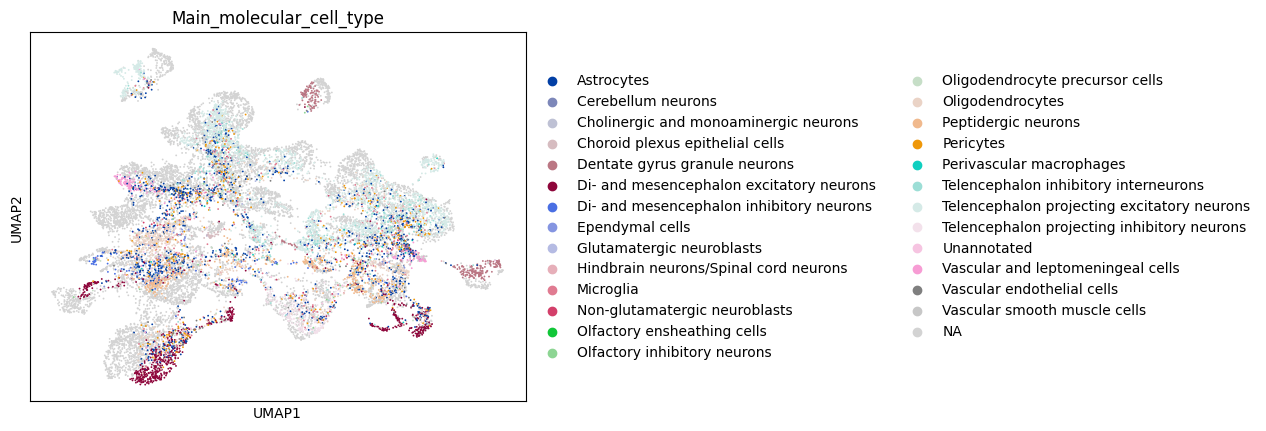

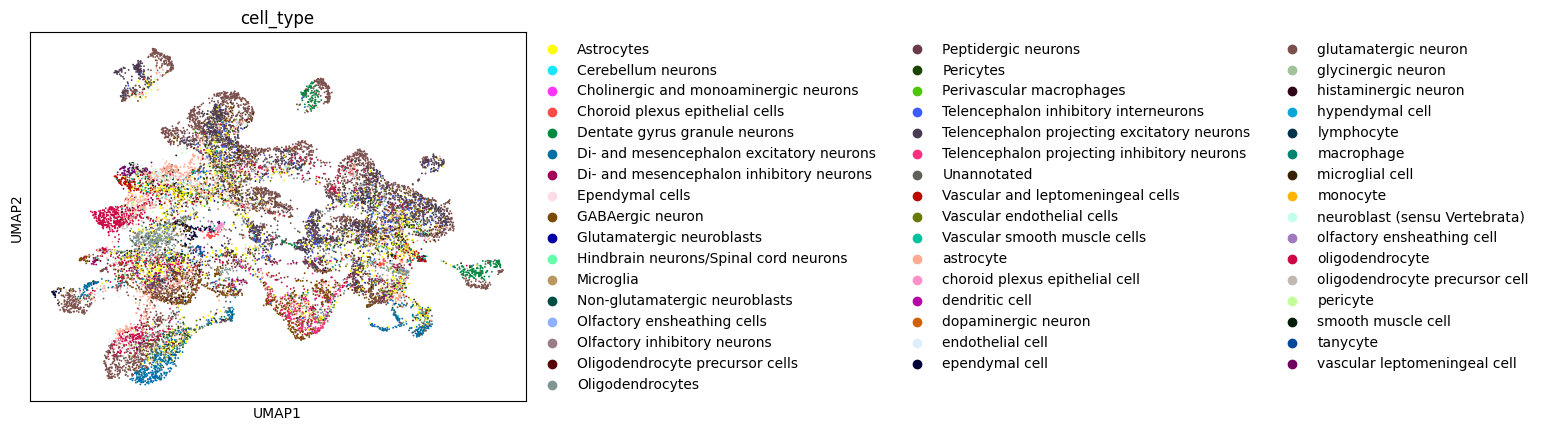

In [20]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'nichecompass_latent_cluster', 'Main_molecular_cell_type', 'cell_type'] # ['major_brain_region', 'Main_molecular_tissue_region']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_actio

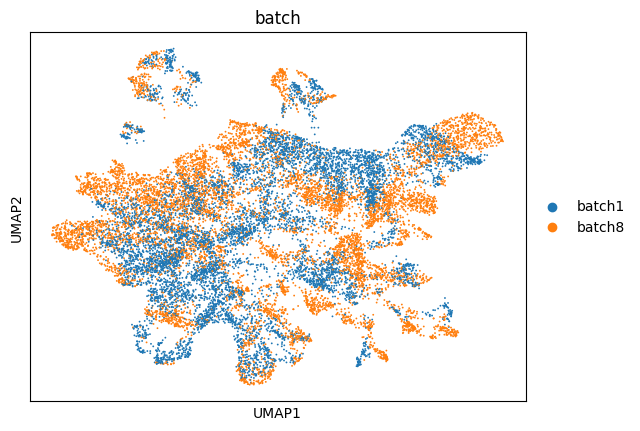

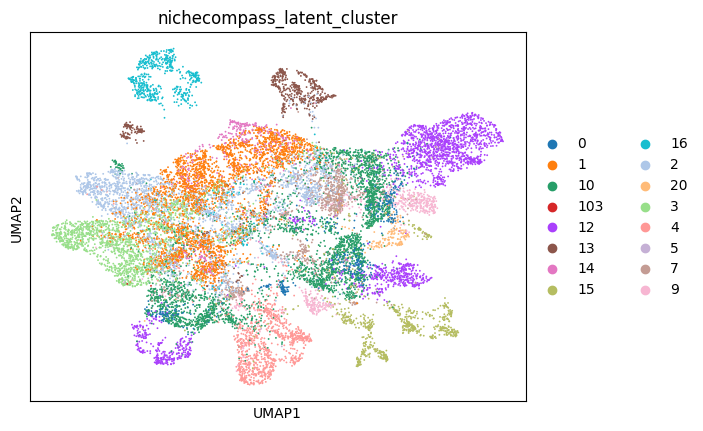

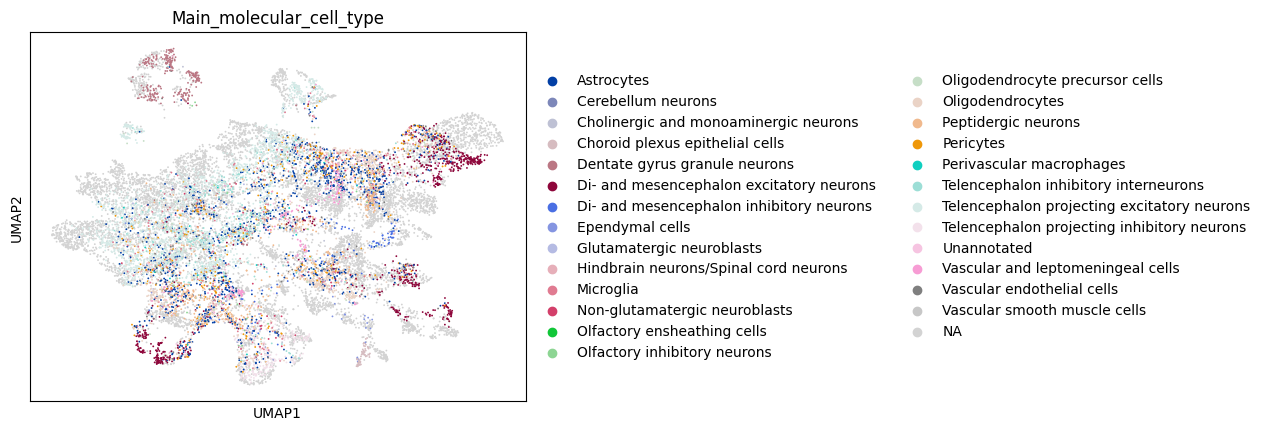

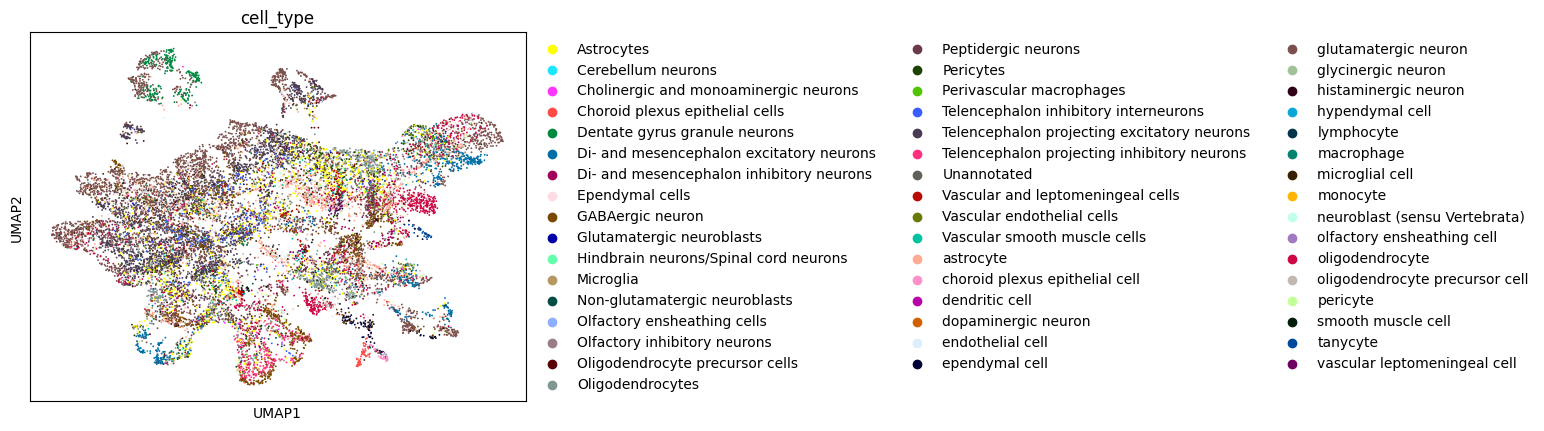

In [21]:
## Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{layer}',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'nichecompass_latent_cluster', 'Main_molecular_cell_type', 'cell_type'] # ['major_brain_region', 'Main_molecular_tissue_region']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

## 3.3 Plot Embedding Similarity Stats

## 3.4 Compute Metrics

In [ ]:
os.makedirs(f'{folder_path}/metrics', exist_ok=True)

labels = ['cell_types', 'major_brain_region']

# NMI & ARI for label cols (neighborhood embedding)
for label in labels:
    cell_type_metrics = clustering_metrics(
        adata,
        emb_key=f'neighborhood_emb_layer_{layer}',
        label_col=label)
    
    metrics_df = pd.DataFrame([cell_type_metrics])
    metrics_df.to_csv(f'{folder_path}/metrics/{label}_metrics{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.csv', index=False)

## 3.5 Plot Loss Curve

In [ ]:
df = pd.read_csv(f'{folder_path}/jepa_r0.csv')
df['loss'] = pd.to_numeric(df['loss'], errors='coerce')

plt.figure(figsize=(10, 6))
plt.plot(df.index,df['loss'])
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

In [ ]:
adata_starmap = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_label/starmap_plus_mouse_cns_batch15.h5ad')
adata_merfish = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_label/merfish_mouse_brain_239-batch_batch82.h5ad')

# Check that genes are the same
(adata_starmap.var != adata_merfish.var).any()

# adata_starmap.X.toarray().sum(1)
# adata_merfish.X.toarray().sum(1)

np.mean(adata_merfish.X.sum(1))

np.mean(adata_starmap.X.sum(1))

adata_concat = adata_starmap.concatenate(adata_merfish)

adata_concat.X = adata_concat.X.toarray() / adata_concat.X.toarray().sum(axis=1).reshape(-1, 1) * 10_000
sc.pp.log1p(adata_concat)

adata_concat.X

adata.X.sum(1x).value_counts()

adata_concat.X[0, :].shape

# Get unique values and their counts
unique_values, counts = np.unique(adata_concat.X[1, :], return_counts=True)

# Print the results
for value, count in zip(unique_values, counts):
    print(f"Value {value} occurs {count} times")

plt.hist(adata_concat.X.toarray(), bins=50, edgecolor='black')

sc.pp.neighbors(adata_concat,
                n_neighbors=15,
                use_rep='X')
sc.tl.umap(adata_concat)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata_concat,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_pca'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

for i in range(len(test_dataset["gene_tokens"])):
    test_dataset["gene_tokens"][i]

top_k = 10

embedding_dict = {i: np.random.rand(768) for i in range(1672)}
averaged_embeddings = []

for tokens in test_dataset["gene_tokens"]:
    # Filter out the zero tokens
    valid_tokens = [token for token in tokens[:top_k] if token != 0]

    # Retrieve embeddings for the valid tokens
    if valid_tokens:
        embeddings = [embedding_dict[token] for token in valid_tokens]
        
        # Calculate the average embedding across the sequence
        avg_embedding = np.mean(embeddings, axis=0)
    else:
        # If no valid tokens, create a zero vector (or handle as desired)
        avg_embedding = np.zeros(768)
    
    # Append the averaged embedding for this observation
    averaged_embeddings.append(avg_embedding)

# Convert the list of averaged embeddings to a numpy array
averaged_embeddings = np.array(averaged_embeddings)

# Assuming adata is your AnnData object
# Store the averaged embeddings in adata.obsm
adata = ad.AnnData(X=averaged_embeddings)  # Initialize adata or use an existing one

adata.obs['batch'] = [element[0] for element in test_dataset['batch_token']]

sc.pp.neighbors(adata,
                n_neighbors=15)
sc.tl.umap(adata)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_random_embed'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

sq.pl.spatial_scatter(adata_starmap,
                      color="major_brain_region",
                      shape=None)

sq.pl.spatial_scatter(adata_merfish,
                      color="major_brain_region",
                      shape=None) 